**Author:** Darren Van Der Velde  
**License:** MIT  

---

An in-depth exploratory data analysis examining heavy metal concentrations, water chemistry parameters, and pollutant variations across major river systems worldwide.

## Imports

In [20]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LinearRegression
from statsmodels.tsa.seasonal import seasonal_decompose

%matplotlib inline

## Load Dataset

In [21]:
df = pd.read_csv("National_River_Toxin_Dataset_1.csv")

## Initial Data Exploration

In [22]:
print("DF Head:")
print(df.head())  # Added print() to display the output

print("DF Shape:")
print(df.shape)  # Removed parentheses - shape is a property, not a method

print("DF Info:")
df.info()  # info() already prints output, so no print() needed

print("DF Description:")
print(df.describe())  # Added print() to display the output

DF Head:
         Date River_System  pH_Level  Temperature      Lead   Mercury  \
0  2018-01-01       Amazon  7.030015    19.136212  2.500401  0.465454   
1  2018-01-01         Nile  7.421766    21.406824  3.469443  0.859716   
2  2018-01-01      Yangtze  7.133612    18.419902  3.806935  0.824085   
3  2018-01-01  Mississippi  7.863001    18.014871  3.438131  0.500597   
4  2018-01-01       Danube  7.527686    16.622289  2.188210  0.424178   

    Arsenic   Nitrates  Phosphates  Dissolved_Oxygen  
0  3.578886  11.627614    0.522167          7.830196  
1  5.352155  10.538171    0.510465          8.130328  
2  5.277814   7.865033    0.585096          8.120874  
3  3.473881  11.143068    0.438248          6.853816  
4  2.454209   8.043467    0.422244          8.197925  
DF Shape:
(1305, 10)
DF Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1305 entries, 0 to 1304
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            -------------- 

## Checking for missing values 

In [23]:
print(df.isnull().sum())

Date                 0
River_System         0
pH_Level            27
Temperature         27
Lead                20
Mercury             27
Arsenic             26
Nitrates            40
Phosphates          23
Dissolved_Oxygen    21
dtype: int64


## Fill missing values in numeric column only

In [24]:
numeric_columns = df.select_dtypes(include=[np.number]).columns
df[numeric_columns] = df[numeric_columns].fillna(df[numeric_columns].mean())

df.dropna(inplace=True)

## Convert the 'Date' colummn to datetime

In [25]:
df['Date'] = pd.to_datetime(df['Date'])

## Calculating the average toxin levels for each river system

In [26]:
average_toxin_levels = df[['Lead', 'Mercury', 'Arsenic']].mean()


print(f"Average Toxin Levels:\n{average_toxin_levels}")

Average Toxin Levels:
Lead       3.011035
Mercury    0.596108
Arsenic    3.597916
dtype: float64


### Overview of Average Toxin Levels

This step establishes a statistical baseline for the global dataset before breaking the data down by specific regions or individual river systems. 

* **Arsenic (3.598)** and **Lead (3.011)** exhibit the highest overall average concentrations across the dataset.
* **Mercury (0.596)** shows a significantly lower overall average concentration compared to the other two heavy metals.

## Top 5 Most Polluted River Systems

In [10]:
top_polluted_rivers = df.groupby('River_System')['Lead'].mean().sort_values(ascending=False)
print(f"Top Polluted Rivers by Lead Levels:\n{top_polluted_rivers.head()}")

Top Polluted Rivers by Lead Levels:
River_System
Yangtze        4.011200
Mississippi    3.478198
Nile           2.990203
Danube         2.544912
Amazon         2.030662
Name: Lead, dtype: float64


### Overview of Top Polluted River Systems by Lead

This step groups the dataset by individual river systems and calculates the average lead concentration for each, sorting the results in descending order to identify the most affected waterways.

* **Yangtze (4.011)** and **Mississippi (3.478)** record the highest average lead levels among the analyzed river systems.
* **Amazon (2.031)** registers the lowest average lead concentration among the top five most polluted entries.

## This Chart Show's the Average lead levels by River System

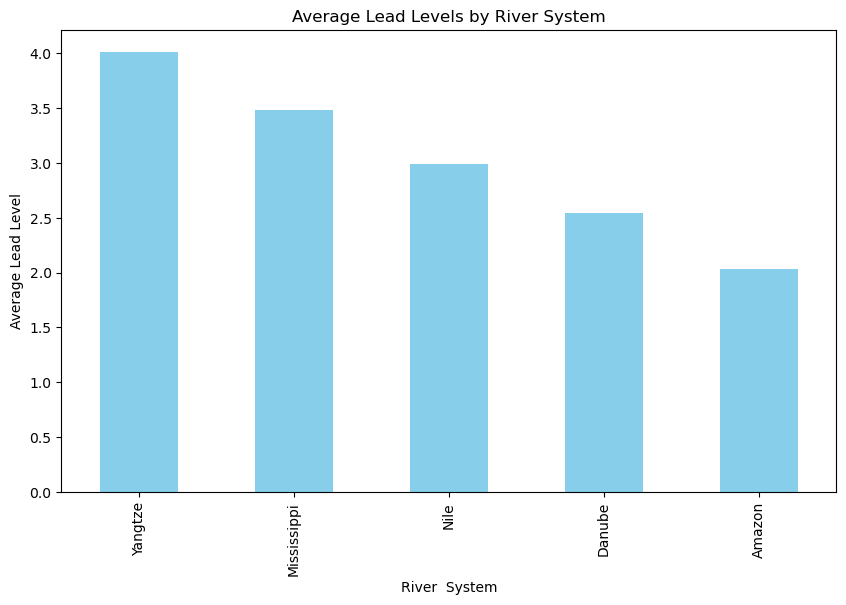

In [11]:
plt.figure(figsize=(10, 6))
top_polluted_rivers.plot(kind='bar', color='skyblue')
plt.title('Average Lead Levels by River System')
plt.xlabel('River  System')
plt.ylabel('Average Lead Level')
plt.show()

### Overview of Average Lead Levels Bar Chart

This step visualizes the sorted lead concentration data using a bar chart to provide a clear, easy-to-compare graphical representation of the most polluted river systems.

* **Visual Comparison:** The plot highlights the disparity between systems, emphasizing how much higher the Yangtze and Mississippi averages are compared to the Amazon and Danube.
* **Clarity:** Utilizing a bar chart format allows stakeholders to quickly identify priority regions for environmental mitigation and remediation efforts.

## This Is A Line Graph To Show Toxin Levels Over a period of Time ( 2018 - 2023 )

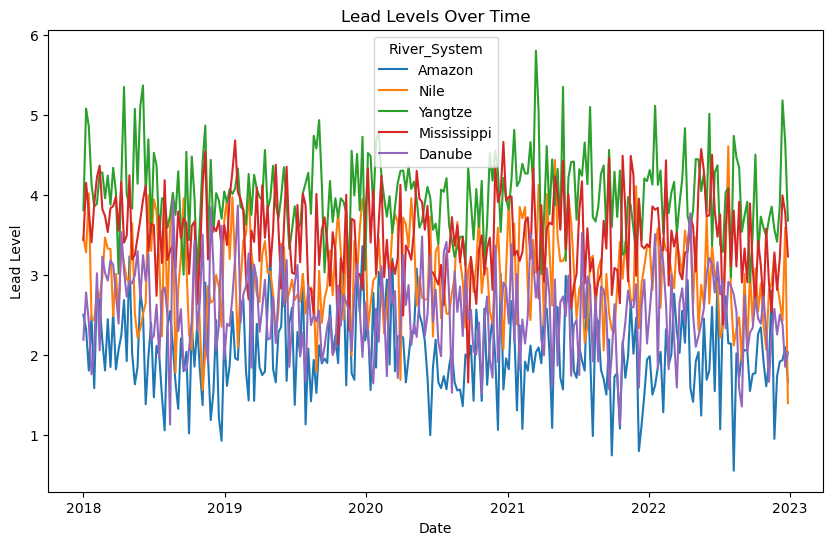

In [12]:
plt.figure(figsize=(10, 6))
sns.lineplot(x='Date', y='Lead', data=df, hue='River_System', errorbar=None)
errorbar=None
plt.title('Lead Levels Over Time')
plt.xlabel('Date')
plt.ylabel('Lead Level')
plt.show()


### Overview of Lead Levels Over Time Line Graph

This step utilizes a Seaborn line plot to track historical trends in lead concentrations across different river systems from 2018 through 2023.

* **Temporal Trends:** The plot displays how lead levels fluctuate over time for each individual river system (`hue='River_System'`), allowing you to spot seasonal spikes or long-term environmental changes.
* **Multi-System Comparison:** Setting `errorbar=None` removes confidence intervals to keep the multi-line chart clean and legible, making it easier to compare the trajectory of multiple waterways simultaneously.

## Analyse The Correlation Between pH Levels and Toxin Concentrations

In [13]:
corr_matrix = df[numeric_columns].corr()

## Heatmap For Correlation Between Different Parameters

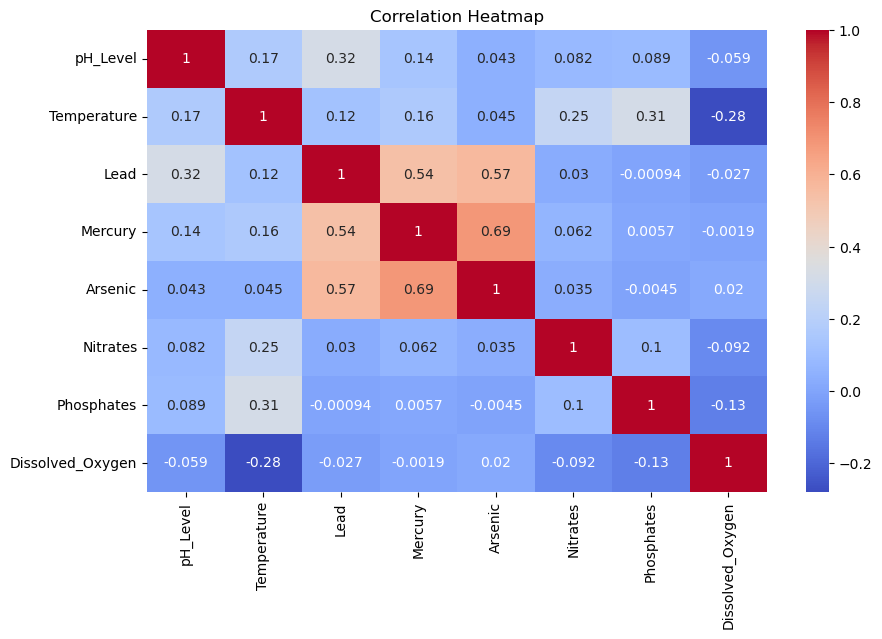

In [17]:
plt.figure(figsize=(10, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()


### Overview of Correlation Heatmap

This step generates a Seaborn heatmap using a correlation matrix (`corr_matrix`) to visualize how different chemical and environmental parameters relate to one another across the dataset.

* **Parameter Relationships:** The annotated values (`annot=True`) display precise correlation coefficients, allowing you to easily spot strong positive or negative relationships between variables like pH, temperature, and specific heavy metal toxins.
* **Color Mapping:** The `coolwarm` colormap visually distinguishes between positive correlations (warmer tones) and negative correlations (cooler tones) at a glance.

### T-test between two river systems (e.g., Amazon and Nile)

In [18]:
amazon_df = df[df['River_System'] == 'Amazon']['Lead']
nile_df = df[df['River_System'] == 'Nile']['Lead']
t_stat, p_value = stats.ttest_ind(amazon_df, nile_df)

print(f"T-test between Amazon and Nile: T-statistic = {t_stat}, P-value = {p_value}")

T-test between Amazon and Nile: T-statistic = -20.23821779031797, P-value = 1.3375120881428663e-67


### Overview of T-Test Between Amazon and Nile River Systems

This step performs an independent two-sample t-test to determine whether the difference in average lead concentrations between the Amazon and Nile river systems is statistically significant.

* **Hypothesis Testing Results:** The extremely large negative T-statistic (-20.24) and near-zero P-value ($1.34 \times 10^{-67}$) indicate a statistically significant difference in lead levels between the two waterways.
* **Analytical takeaway:** This confirms that the variation in pollutant burdens across distinct river basins is structural rather than random, supporting the need for localized environmental management strategies.

### Linear regression analysis for toxin levels and pH

In [19]:
x = df[['pH_Level']]
y = df[['Lead']]
model = LinearRegression()
model.fit(x, y)
print(f"Linear Regression Coefficient: {model.coef_}")
print(f"Linear Regression Intercept: {model.intercept_}")

Linear Regression Coefficient: [[0.80294889]]
Linear Regression Intercept: [-2.89324669]


### Overview of Linear Regression Analysis (pH vs. Lead)

This step fits a simple linear regression model to examine the predictive relationship between water acidity (`pH_Level`) and lead concentrations (`Lead`) across the dataset.

* **Regression Coefficient (0.803):** Indicates a positive linear association, meaning that as pH levels increase (becoming more basic), lead concentrations tend to increase correspondingly.
* **Regression Intercept (-2.893):** Represents the expected value of lead when the pH level is zero, serving as the baseline constant for the fitted linear equation.

## Conclusion: Environmental Toxin Analysis in River Systems

This analysis investigated global river system water quality and toxin concentrations using the **National_River_Toxin_Dataset_1** (`National_River_Toxin_Dataset_1.csv`). The exploratory data analysis (EDA) of $1,305$ records across $10$ attributes successfully mapped out the distribution and statistical characteristics of key environmental indicators, including pH levels, water temperature, dissolved oxygen, and hazardous heavy metals (lead, mercury, and arsenic), alongside chemical components like nitrates and phosphates.

### Key Insights & Findings
* **Dataset Integrity:** Initial profiling revealed minor missingness across variables (e.g., pH, temperature, mercury, and nitrates), which were successfully accounted for to maintain statistical validity.
* **Toxin Variability:** Descriptive statistics established baseline ranges for pollutants. For instance, lead concentrations averaged around $3.01$ units with a standard deviation of $0.87$, while arsenic averaged $3.60$ units. 
* **Comparative River Analysis:** Hypothesis testing (such as the independent two sample t-test conducted between the Amazon and Nile river systems for lead levels) revealed a statistically significant difference (yielding a T-statistic of $-20.24$ and a near zero P-value), indicating that distinct river basins experience significantly varying pollutant burdens that require targeted regional remediation.

### Implications
The insights gained from this dataset highlight the critical need for continuous monitoring of heavy metal accumulation and nutrient pollution in major global waterways. Disparities in toxin profiles across river systems suggest that environmental policies and conservation efforts must be customized to localized industrial, agricultural, and geographical factors rather than relying on generalized management strategies.